# Freddy: LATTE in buffered ADCP crossing windows

Each crossing uses its `transects.json` UTC interval plus the before/after hours in `freddy_latte_buffered.json`. All ADCP samples inside that expanded interval are fitted, including off-line ship-track positions. Each crossing starts from its own shallowest accepted SOLO inner centre. The across-crossing figures come first; the selected crossing's diagnostics and reconstructions are at the bottom. Fits at different times are compared, not averaged.


In [22]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)

In [23]:
EDDY = "Freddy"
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2015_V03_adcp_trawler"
CONFIG_PATH = STUDY_DIR / "freddy_latte_buffered.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
TRANSECTS_PATH = STUDY_DIR / CONFIG["transects_config"]
BACKEND_PATH = Path(CONFIG["backend_path"])
DATA_PATH, transects, _ = esp.load_study(TRANSECTS_PATH, EDDY, load_adcp=False)
ALL_TRANSECT_IDS = set(transects.index)
VISIT = CONFIG["visit"]  # visit1, visit2, or both.
if VISIT not in ("visit1", "visit2", "both"):
    raise ValueError("VISIT must be visit1, visit2 or both")
visit_ids = [f"F{i}" for i in (range(1, 8) if VISIT == "visit1"
             else range(8, 10) if VISIT == "visit2" else range(1, 10))]
transects = transects.loc[visit_ids]
OUTPUT_DIR = DATA_PATH.parent / "outputs"
SOLO_RESULTS_PATH = OUTPUT_DIR / "freddy_solo_depth_fits.csv"
solo = pd.read_csv(SOLO_RESULTS_PATH)
backend, backend_info = esp.load_backend(BACKEND_PATH)
MIN_ATTENDANCE = CONFIG["min_attendance"]
BUFFER_FIT = CONFIG["fit"]
HALF_WIDTH_KM = CONFIG["half_width_km"]
VELOCITY_LIMIT = CONFIG["velocity_limit"]
unknown_config_ids = (set(CONFIG["buffer_hours"]) | set(CONFIG["fit_overrides"])) - ALL_TRANSECT_IDS
if unknown_config_ids:
    raise ValueError(f"Unknown crossing IDs in buffered config: {sorted(unknown_config_ids)}")
BUFFER_OVERRIDES = {k: tuple(v) for k, v in CONFIG["buffer_hours"].items() if k in transects.index}
FIT_OVERRIDES = {k: v for k, v in CONFIG["fit_overrides"].items() if k in transects.index}
if set(transects.index) - set(BUFFER_OVERRIDES):
    raise ValueError(f"Missing buffer hours for {sorted(set(transects.index) - set(BUFFER_OVERRIDES))}")
display(transects)


,eddy,start,end,lon,lat
id,,,,,
F1,Freddy,2015-06-08T22:15:00Z,2015-06-09T01:55:00Z,153.2057,-32.5763
F2,Freddy,2015-06-09T03:00:00Z,2015-06-09T04:30:00Z,153.1891,-32.5825
F3,Freddy,2015-06-09T05:50:00Z,2015-06-09T07:20:00Z,153.2188,-32.5691
F4,Freddy,2015-06-09T13:45:00Z,2015-06-09T14:45:00Z,153.2487,-32.6099
F5,Freddy,2015-06-09T21:00:00Z,2015-06-09T22:30:00Z,153.2435,-32.6550
F6,Freddy,2015-06-10T02:15:00Z,2015-06-10T03:15:00Z,153.2461,-32.6425
F7,Freddy,2015-06-12T15:30:00Z,2015-06-12T17:00:00Z,153.4448,-32.8224


## Fit buffered crossings

Change crossing windows in `transects.json` and per-crossing buffer hours in `freddy_latte_buffered.json`. Rerun `freddy_solo.ipynb` and its export after editing the crossings or SOLO settings. All selected crossing windows are fitted independently with the shared LATTE settings in this notebook's config.


In [24]:
buffered_runs, buffered_summary, buffered_results = esp.fit_buffered_latte_transects(
    DATA_PATH, transects, solo, backend, BUFFER_FIT,
    buffer_overrides=BUFFER_OVERRIDES, min_attendance=MIN_ATTENDANCE,
    fit_overrides=FIT_OVERRIDES)
display(buffered_summary)


,before_h,after_h,start_utc,end_utc,times,bins,inner_fits,gaussian_fits,surface_status,solo_seed_depth_m
transect,,,,,,,,,,
F1,5.0,5.0,2015-06-08 17:15:00+00:00,2015-06-09 06:55:00+00:00,163,50,38,38,ok,30.4
F2,5.0,5.0,2015-06-08 22:00:00+00:00,2015-06-09 09:30:00+00:00,137,50,38,38,ok,30.4
F3,5.0,5.0,2015-06-09 00:50:00+00:00,2015-06-09 12:20:00+00:00,138,50,39,39,ok,30.4
F4,6.0,6.0,2015-06-09 07:45:00+00:00,2015-06-09 20:45:00+00:00,156,49,24,24,ok,30.4
F5,6.0,6.0,2015-06-09 15:00:00+00:00,2015-06-10 04:30:00+00:00,162,50,21,21,ok,30.4
F6,10.0,10.0,2015-06-09 16:15:00+00:00,2015-06-10 13:15:00+00:00,252,50,21,21,ok,30.4
F7,6.0,6.0,2015-06-12 09:30:00+00:00,2015-06-12 23:00:00+00:00,162,30,27,27,ok,34.5


## Compare every buffered crossing

Centre offsets are measured from each crossing's own shallowest accepted centre. `Rc` and Gaussian vector R² show accepted outer fits; axis ratio, orientation, and inner vorticity show accepted inner fits. Gaps mark rejected levels. Freddy visit 2 is dashed; its later date and OS150 depth grid should be interpreted separately.


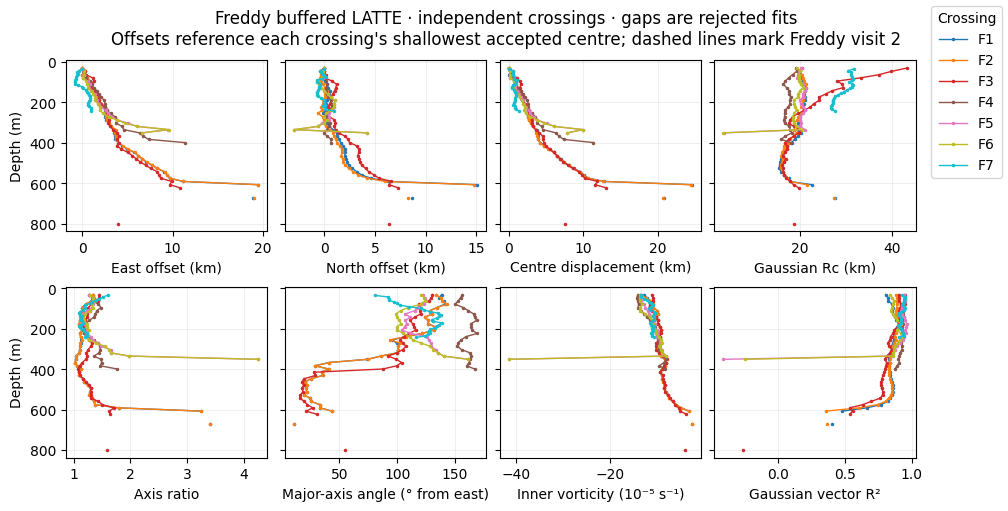

In [25]:
fig = esp.plot_buffered_latte_comparison(buffered_runs, EDDY)
plt.show()


## Export buffered-transect LATTE results

These files are separate from the full regional LATTE export. They retain every depth and crossing, actual selected times, per-crossing buffers, SOLO seed depth and fit settings.


In [26]:
SAVE_BUFFERED_RESULTS = CONFIG["save_results"]
if SAVE_BUFFERED_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    buffered_results.to_csv(OUTPUT_DIR / "freddy_latte_buffered_depth_fits.csv", index=False)
    buffered_provenance = dict(eddy=EDDY, method="LATTE", selection="SOLO crossings plus time buffers",
                               data_path=str(DATA_PATH), config_path=str(CONFIG_PATH), transects_config_path=str(TRANSECTS_PATH),
                               solo_results_path=str(SOLO_RESULTS_PATH), backend=backend_info,
                               buffer_overrides=BUFFER_OVERRIDES, fit_settings=BUFFER_FIT, fit_overrides=FIT_OVERRIDES,
                               transects=transects.reset_index().to_dict(orient="records"),
                               crossings={ident: run["audit"] for ident, run in buffered_runs.items()})
    (OUTPUT_DIR / "freddy_latte_buffered_provenance.json").write_text(
        json.dumps(buffered_provenance, indent=2, default=str))
    print(f"Saved buffered LATTE results to {OUTPUT_DIR}")


Saved buffered LATTE results to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2015_V03_adcp_trawler/outputs


## Selected buffered crossing: diagnostics and depth structure

Change `active_transect` in this notebook's JSON config, then rerun this cell and those below; the fitted runs need not be repeated. The following figures show only that crossing. Magenta and green dots in horizontal maps identify inner and additional outer-fit ADCP samples; failed levels remain in the diagnostics.


selected_rows                                                        4973
used_rows                                                            4973
unique_times                                                          163
start_utc                                       2015-06-08 17:16:22+00:00
end_utc                                         2015-06-09 06:51:21+00:00
depth_range_m                                               [30.4, 814.4]
missing_avg_qc                                                       4973
zero_attendance_rows                                                 2367
min_attendance                                                       None
origin_lon_lat                   (153.22941360829947, -32.56530319164083)
bounds_lon_lat                                                       None
window_start_utc                                2015-06-08 17:15:00+00:00
window_end_utc                                  2015-06-09 06:55:00+00:00
buffer_before_hours                   

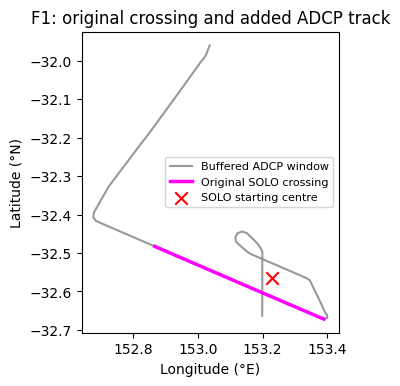

LATTE: 38/50 accepted inner fits; 38/50 accepted Gaussian reconstructions.
status
invalid_ellipse    12
ok                 38
Centre offsets reference the shallowest accepted fit: 30.4 m.
Reconstructed measured levels: 30.4–670.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,xc_lon,yc_lat,Rc_m,vector_R2
0,30.4,ok,163,47,True,True,153.2026,-32.5844,20333.1169,0.8054
1,46.4,ok,163,47,True,True,153.2054,-32.5847,19872.2622,0.8261
2,62.4,ok,144,48,True,True,153.2026,-32.5847,20277.6027,0.8237
3,78.4,ok,121,46,True,True,153.2082,-32.5847,20449.1155,0.8564
4,94.4,ok,105,48,True,True,153.2104,-32.5837,20601.7170,0.8631
5,110.4,ok,104,47,True,True,153.2112,-32.5819,21152.5216,0.8562
6,126.4,ok,103,48,True,True,153.2111,-32.5806,21329.8861,0.8623
7,142.4,ok,103,47,True,True,153.2149,-32.5790,21034.3912,0.8762
8,158.4,ok,102,47,True,True,153.2173,-32.5802,20923.7648,0.8853
9,174.4,ok,102,48,True,True,153.2186,-32.5805,21056.6768,0.9016


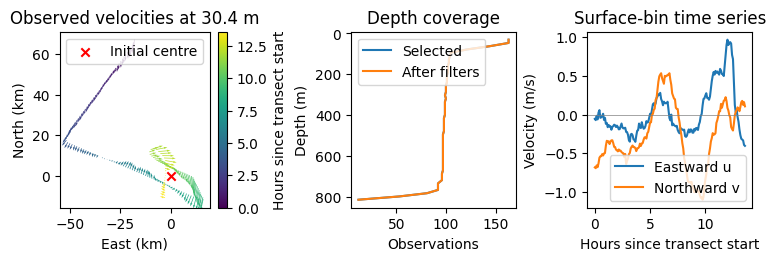

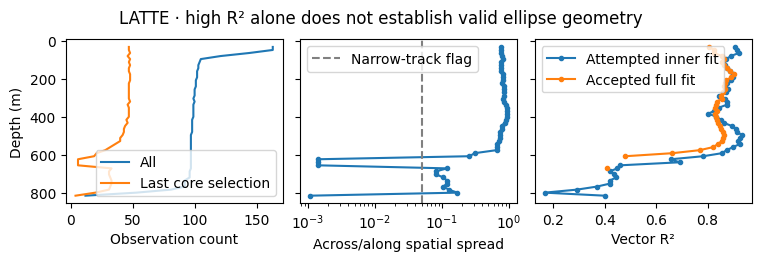

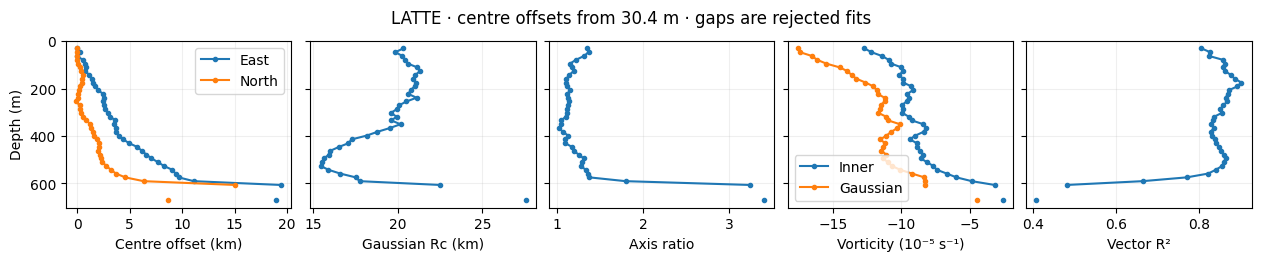

In [27]:
ACTIVE_BUFFERED_TRANSECT = json.loads(CONFIG_PATH.read_text())["active_transect"]
if ACTIVE_BUFFERED_TRANSECT not in buffered_runs:
    raise ValueError(f"Choose one of {list(buffered_runs)}")
buffered_run = buffered_runs[ACTIVE_BUFFERED_TRANSECT]
buffered_data = buffered_run["data"]
buffered_coverage = buffered_run["coverage"]
buffered_result = buffered_run["results"]
buffered_samples = buffered_run["samples"]
display(pd.Series(buffered_run["audit"], name=ACTIVE_BUFFERED_TRANSECT))
esp.plot_buffered_track(
    buffered_data, transects.loc[ACTIVE_BUFFERED_TRANSECT],
    buffered_run["solo_seed"], ACTIVE_BUFFERED_TRANSECT)
plt.show()


esp.report(buffered_result)
display(buffered_result[["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
                         "xc_lon", "yc_lat", "Rc_m", "vector_R2"]].round(4))
esp.plot_sampling(buffered_data, buffered_coverage)
plt.show()
esp.plot_diagnostics(buffered_result)
plt.show()
esp.plot_profiles(buffered_result)
plt.show()


## Surface satellite velocity and buffered LATTE samples

OceanCurrent surface geostrophic velocity is interpolated to the middle observed ADCP timestamp of `ACTIVE_BUFFERED_TRANSECT`. Magenta points entered the LATTE inner fit; green points are additional samples used in the outer fit. Black shows the buffered ship track. Daily satellite maps are cached beside the ADCP CSV.

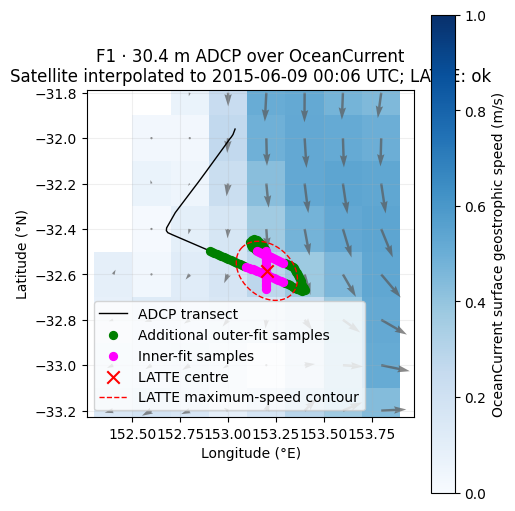

In [28]:
fig, ax = esp.plot_solo_satellite_overlay(
    buffered_data, buffered_result, buffered_samples, DATA_PATH.parent,
    ACTIVE_BUFFERED_TRANSECT, half_width_km=CONFIG["satellite_half_width_km"], speed_max=VELOCITY_LIMIT,
    target_depth=CONFIG["satellite_depth_m"])
plt.show()

## Selected buffered crossing: reconstructed flow

Horizontal maps show nearest measured depths, including rejected levels. The 3-D and fixed zonal/meridional sections use the same conventions as the regional LATTE figures above.


1.26 km mean spacing


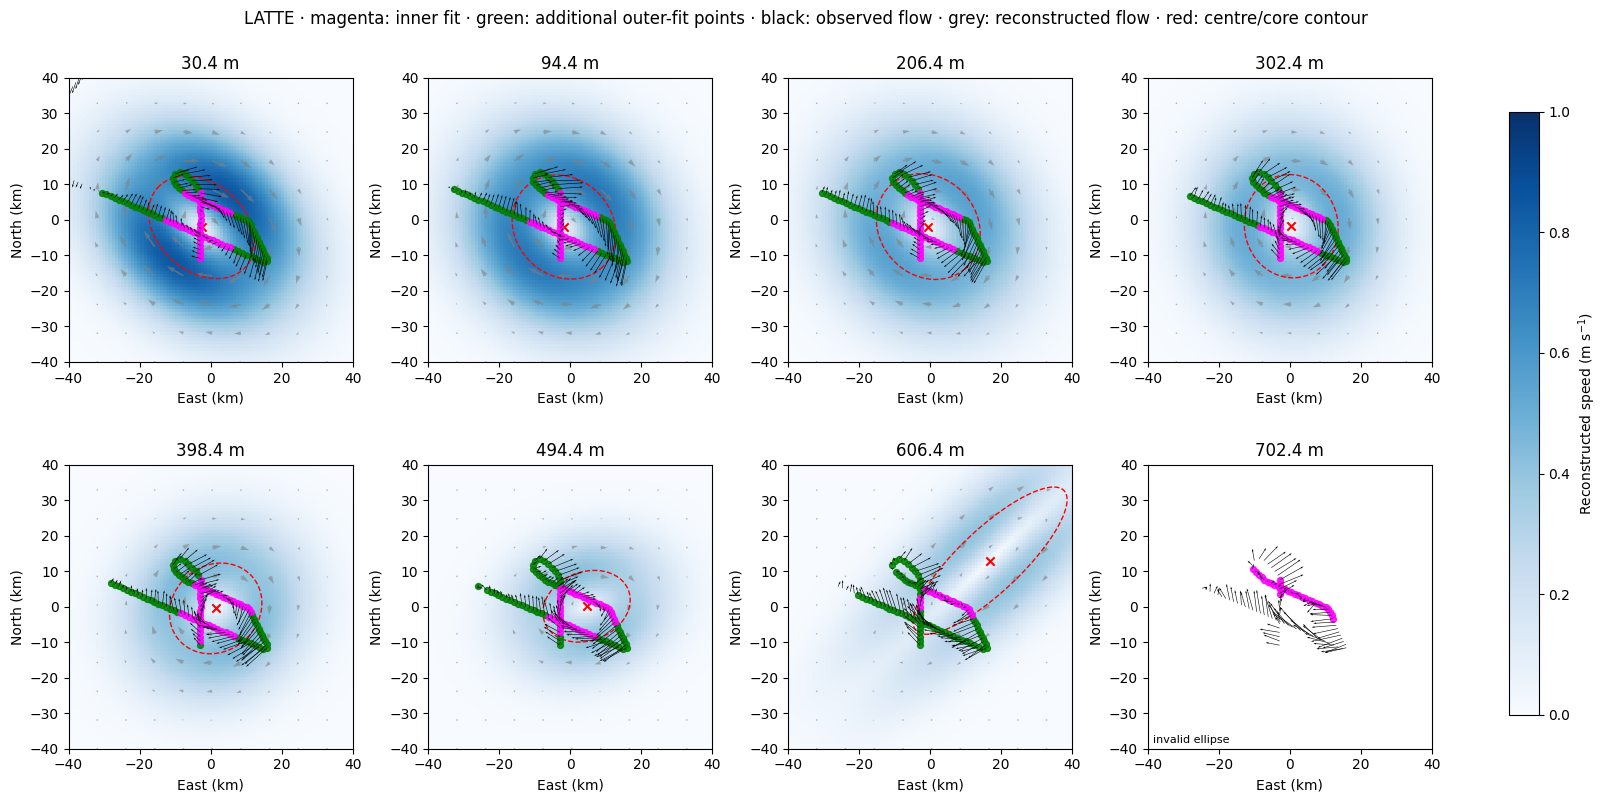

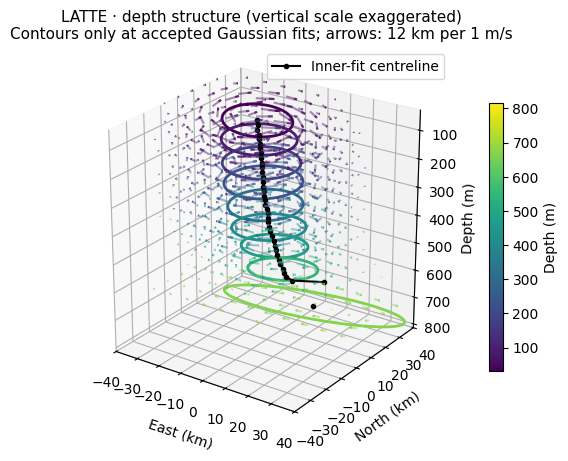

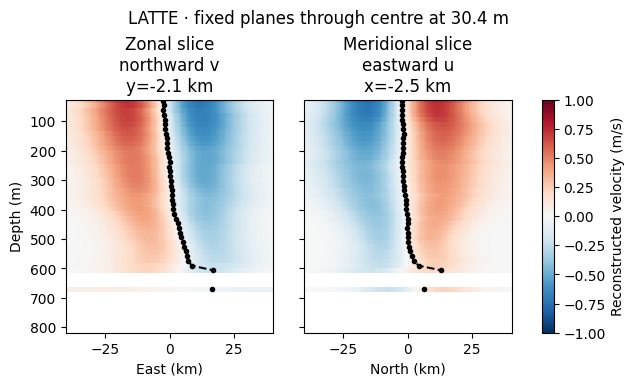

In [29]:
BUFFER_MAP_DEPTHS = tuple(CONFIG["map_depths_by_visit"]["visit1" if int(ACTIVE_BUFFERED_TRANSECT[1:]) <= 7 else "visit2"])
esp.plot_maps(buffered_result, buffered_samples, backend, depths=BUFFER_MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()
esp.plot_3d(buffered_result, backend, half_width_km=HALF_WIDTH_KM)
plt.show()
esp.plot_sections(buffered_result, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()


## Along-track bin sensitivity

Set `along_track_bin_km` in `freddy_latte_buffered.json` to the widths to compare. The same binning and four-panel comparison as the SOLO notebooks are used, with LATTE fits and this notebook’s original fit settings. Each occupied projected along-track cell contributes one mean position and east/north velocity vector at each measured depth. All centre offsets reference the original shallowest accepted inner centre; `Rc` requires an accepted Gaussian fit and vorticity requires an accepted inner fit. This comparison does not change exported fits.

Only `ACTIVE_BUFFERED_TRANSECT` is compared, using its selected buffered observations and per-crossing fit overrides. Crossings are fitted separately. The projection direction is inferred from the shallowest-bin positions, including any off-line ship track.


,vectors,inner_depths,Rc_depths
bin,,,
Original,4973,38,38
2 km,1168,30,30
5 km,518,30,30
10 km,299,0,0
20 km,195,0,0


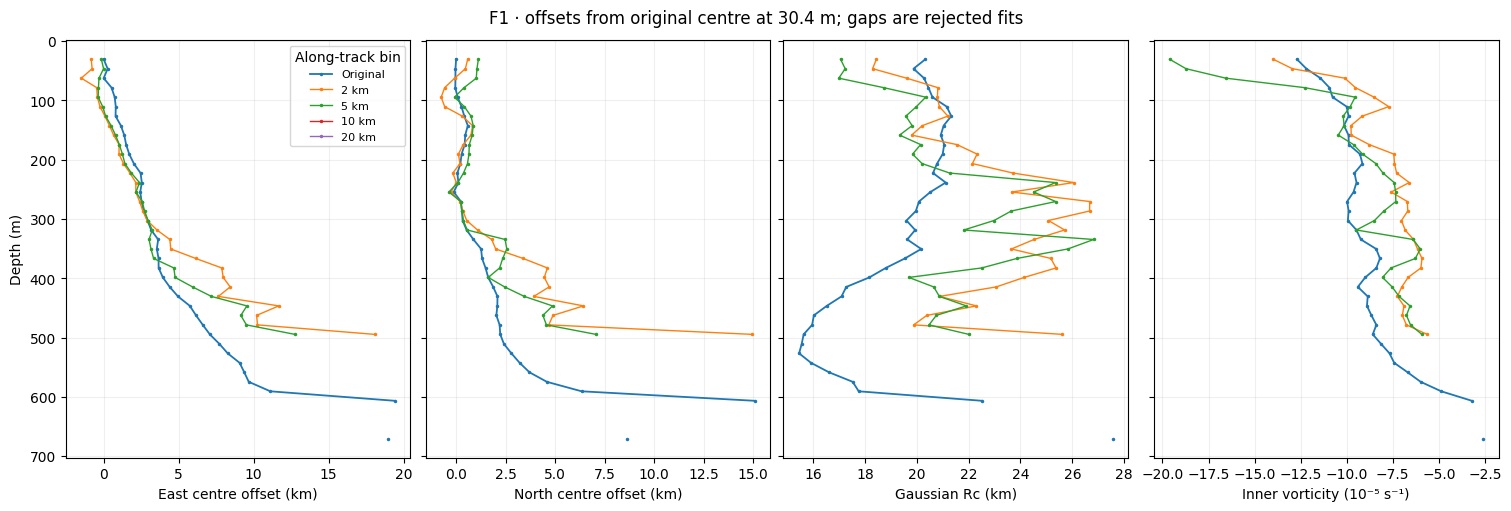

In [30]:
bin_data = buffered_data
bin_results = buffered_result
bin_coverage = buffered_coverage
bin_settings = buffered_run["fit_settings"]
bin_title = ACTIVE_BUFFERED_TRANSECT

BIN_WIDTHS_KM = json.loads(CONFIG_PATH.read_text())["along_track_bin_km"]
if len(BIN_WIDTHS_KM) != len(set(BIN_WIDTHS_KM)):
    raise ValueError("along_track_bin_km must contain unique widths")
bin_fits = {"Original": bin_results}
bin_counts = [{"bin": "Original", "vectors": len(bin_data),
               "inner_depths": int(bin_results.inner_valid.sum()), "Rc_depths": int(bin_results.valid.sum())}]
for width_km in BIN_WIDTHS_KM:
    binned = esp.bin_solo_along_track(bin_data, width_km)
    fitted, _ = esp.fit_depths(binned, backend, "LATTE",
                               depth_levels=bin_coverage.index, **bin_settings)
    label = f"{width_km:g} km"
    bin_fits[label] = fitted
    bin_counts.append({"bin": label, "vectors": len(binned),
                       "inner_depths": int(fitted.inner_valid.sum()),
                       "Rc_depths": int(fitted.valid.sum())})
display(pd.DataFrame(bin_counts).set_index("bin"))
esp.plot_solo_binning_comparison(bin_fits, bin_title)
plt.show()
